<table>
    <tr>
        <td style="text-align:left">
            <img src="https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcR9ItLTT_F-3Q30cu7ZCCoKmuFGBt22pe7pNA" alt="Logo Universidad" width="300"/>
        </td>
        <td>
            Departamento de Ciencias de la Computación y de la Decisión<br>
            Facultad de Minas<br>
            Universidad Nacional de Colombia<br>
            Optimizacion e IA 2026-2S<br><br>
            Docente: Maria Constanza Torres Madronero<br>
            <br>
            Contribuciones a la guia por: <br>
            - Deimer Miranda Montoya (2023)<br>
            - Luis Fernando Becerra Monsalve (2024)
        </td>    
        </td>    
    </tr>
</table>

### Optimización de funciones

Vamos a comparar el desempeño de los optimizadores gradiente descendente y algoritmo genético. Para ello usaremos una función no convexa con la cual trabajamos en la Practica 1.


In [1]:
import numpy as np
from numpy.random import rand
import matplotlib.pyplot as plt
from matplotlib import cm

$f(x,y)=(x^2+y-11)^2+(x+y^2-7)^2$

In [2]:
#Minimizacion de una funcion 2D
#f(x,y)=(x^2+y-11)^2+(x+y^2-7)^2
def objective_func(solution):
  term1 = (solution[0]**2+solution[1]-11)**2
  term2 = (solution[0]+solution[1]**2-7)**2
  return term1+term2

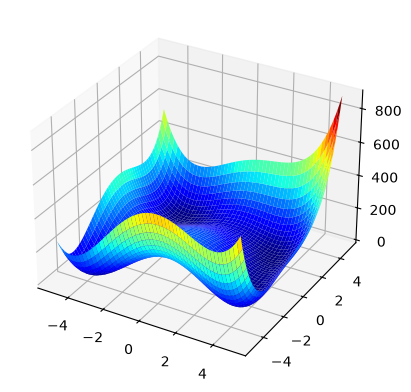

In [3]:
#Grafica de la funcion
x = np.linspace(-5, 5, 1000)
y = np.linspace(-5, 5, 1000)
xv, yv = np.meshgrid(x, y)
feval = objective_func([xv,yv])
ax = plt.figure().add_subplot(111,projection='3d')
ax.plot_surface(xv, yv, feval, cmap=cm.jet)

### Gradiente descendiente

Recordemos el método del gradiente descendiente:
1. Necesitamos conocer la primera derivada de la función objetivo: el gradiente. Para nuestro ejemplo, dado que tenemos una función en dos dimensiones, el gradiente será un vector con dos componentes.


In [4]:
#Funcion que evalua el gradiente en un punto solucion
def derivative(X):
  x = X[0]
  y = X[1]
  term0 = 4*x**3+4*x*y-42*x+2*y**2-14
  term1 = 2*x**2+4*x*y+4*y**3-26*y-22
  gradiente = np.array([term0,term1])
  return gradiente

2. El algoritmo iterativo: cada iteración proporciona una posible solución de la función de optimización. El punto inicial lo seleccionamos de forma aleatoria, y lo actualizamos en cada iteración restando el gradiente escalado con el paso de aprendizaje.

In [5]:
#Funcion del gradiente descendente
def gradient_descent(objective_func, derivative, bounds, n_iter, step_size):
  # Generamos el punto inicial de forma aleatoria
  solution0 = bounds[:,0]+rand(len(bounds))*(bounds[:,1]-bounds[:,0])
  solution1 = bounds[:,0]+rand(len(bounds))*(bounds[:,1]-bounds[:,0])
  solution = np.array([solution0,solution1])
	# Algoritmo iterativo
  for i in range(n_iter):
		#1. Calculo del gradiente
    gradiente = derivative(solution)
		#2. Actualizacion de la solucion
    solution = solution - step_size*gradiente
  	#3. Evaluacion de la solucion
    solution_eval = objective_func(solution)
    #print('>%d f(%s) = %.5f' % (i, solution, solution_eval))
  return solution

In [6]:
# Deliminatos el rango de los datos
bounds = np.asarray([[-4.0, 4.0]])
# Definimos el numero de iteraciones
n_iter = 500
# Seleccionamos la longitud del paso
step_size = 0.01
# Aplicamos el algoritmo de gradiente descendente
solution = gradient_descent(objective_func, derivative, bounds, n_iter, step_size)
#Guardamos la solucion para la comparacion
xopGD, yopGD = solution
fevalGD = objective_func(solution)

[7.88860905e-31]


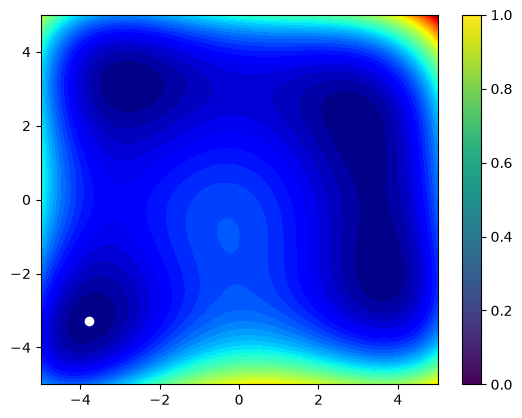

In [7]:
#Grafica de los contornos y punto optimo
plt.contourf(xv, yv, feval, levels=50, cmap='jet')
plt.scatter(xopGD, yopGD,c='white',marker='o')
plt.colorbar()
print(fevalGD)

### Algoritmo Genético
En la actualidad, coexisten diversas librerías especializadas en la implementación de métodos metaheurísticos. No obstante, debido a que se trata de un campo de investigación en continuo desarrollo, representa un desafío identificar frameworks que concentren una amplia taxonomía de algoritmos y que faciliten, de manera estandarizada, su análisis comparativo.
Entre las soluciones de software más destacadas en este dominio se encuentran:
* PyGAD: librería de código abierto orientada al despliegue de algoritmos genéticos y a la optimización de arquitecturas de aprendizaje automático.
* MEALPY: framework que integra más de 230 algoritmos de optimización, diseñado para la resolución de funciones continuas y la optimización de hiperparámetros.
* pymetaheuristic: repositorio que agrupa aproximadamente 400 variantes metaheurísticas pertenecientes a diversas familias algorítmicas.

En esta primera parte, el objeto de estudio se centrará exclusivamente en la evaluación y aplicación de PyGAD.





In [ ]:
#Instalacion de la libreria
#!pip install pygad

  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)

   ---------------------------------------- 0/2 [cloudpickle]
   -------------------- ------------------- 1/2 [pygad]
   -------------------- ------------------- 1/2 [pygad]
   -------------------- ------------------- 1/2 [pygad]
   -------------------- ------------------- 1/2 [pygad]
   -------------------- ------------------- 1/2 [pygad]
   -------------------- ------------------- 1/2 [pygad]
   -------------------- ------------------- 1/2 [pygad]
   -------------------- ------------------- 1/2 [pygad]
   -------------------- ------------------- 1/2 [pygad]
   -------------------- ------------------- 1/2 [pygad]
   -------------------- ------------------- 1/2 [pygad]
   -------------------- ------------------- 1/2 [pygad]
   ---------------------------------------- 2/2 [pygad]



In [9]:
#Importar libreria pygad
import pygad

Los algoritmos genéticos son de aptitud, entonces, es de maximización y no de minimización

In [10]:
#Paso 1: Definire funcion fitness (funcion de aptitud)
#Uno de los parametros para entrenar el algoritmo genetico es la funcion fitness,
#la cual debe ser definida por el usuario. Esta funcion debe ser una funcion de
#maximizacion, de tal forma que el valor mas alto de aptitud sera retornado.
#La funcion puede retornar un unico valor o un arreglo. Esta funcion debe tener
#tres parametros de entrada.
#Parametro 1: La instancia de la clase GA
#Parametro 2: La(s) solucion(s) para calcular la funcion fitness
#Parametro 3: Los indices de la solucion en la poblacion



def fitness_func(ga_instance, solution, solution_idx):
    #Llamamos nuestra funcion objetivo
    
    output = objective_func(solution)

    #Calculamos el fitness (Convertimos el problema de minimizacion a maximizacion)

    fitness = 1.0 / (1.0 + output)
    return fitness

- numero de generaciones: numero de iteraciones

- Numero de soluciones a ser seleccionadas como padres

- Numero de soluciones por poblacion: más computo entre más soluciones por poblacion --> al mismo tiempo validando 20 puntos

- Número de genes: valores codificados: regersión es uno para X y otro para Y --> caracteristicas y target --> dimensiones del problema

- Rangos iniciales para la poblacion inicial: punto inicial lo sacamos del gradiente descendiente

- Numero de padres a mantener en la poblacion: no reemplazar los padres, sino mantener los x mejores 

- Tipo de cruce: en un solo punto, dos puntos, uniforme

- Probabilidad para realizar el cruze: 0.5, el 50% de las veces se va a hacer un cruce

- Probabilidad de mutacion: para que no salta mucho --> pequeño


----> se puede seleccionar más generaciones para mejorar el modelo



In [11]:
#Paso 2: Preparamos los parametros para correr el algoritmo genetico e instanciamos el modelo
ga_instance = pygad.GA(
                       num_generations= 200, #Numero de generaciones
                       num_parents_mating = 6, #Numero de soluciones a ser seleccionadas como padres
                       fitness_func = fitness_func, #Establecer la funcion fitness
                       sol_per_pop = 20,#Numero de soluciones por poblacion
                       num_genes = 2, #Numero de genes en la solucion
                       init_range_low=-4, #Rangos iniciales para la poblacion inicial
                       init_range_high=4,
                       #Metodo para la seleccion de padres, #"rws": Ruleta,#"tournament": Torneo
                       parent_selection_type='tournament',
                       keep_parents=3, #Numero de padres a mantener en la poblacion
                       crossover_type= 'single_point', #Tipo de cruce: en un solo punto, dos puntos, uniforme
                       crossover_probability = 0.5, #Probabilidad para realizar el cruze
                       mutation_type= 'random', #Tipo de mutacion
                       mutation_probability=0.1 #Probabilidad de mutacion
                       ) 

c:\Users\50649\.conda\envs\ia_opt\Lib\site-packages\pygad\utils\validation.py:459: UserWarning: keep_elitism (=1) takes precedence over keep_parents (=3). Set keep_elitism=0 to retain parents instead.
  warnings.warn(f'keep_elitism (={self.keep_elitism}) takes precedence over keep_parents (={self.keep_parents}). Set keep_elitism=0 to retain parents instead.')


In [12]:
#Corremos el algoritmo
ga_instance.run()

In [13]:
#Extraemos la mejor solucion
solution, solution_fitness, solution_idx = ga_instance.best_solution()
print(f"Parameters of the best solution : {solution}")
print(f"Fitness value of the best solution = {solution_fitness}")

prediction = objective_func(solution)
print(f"Valor optimo para la funcion: = {prediction}")

#Guardamos la solucion para la comparacion
xopAG, yopAG = solution
fevalAG = prediction

Parameters of the best solution : [2.99748508 1.99434958]
Fitness value of the best solution = 0.9989419980483069
Valor optimo para la funcion: = 0.0010591225053709348


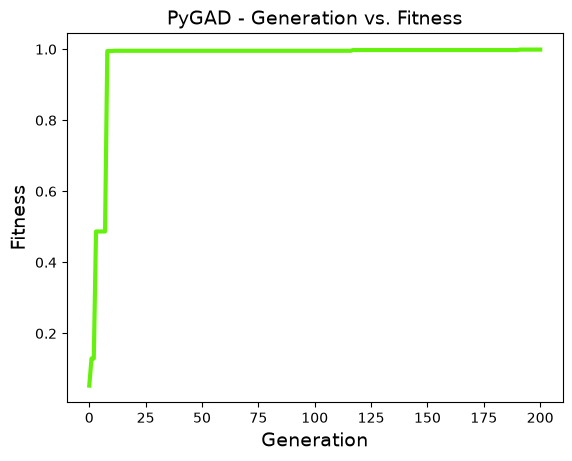

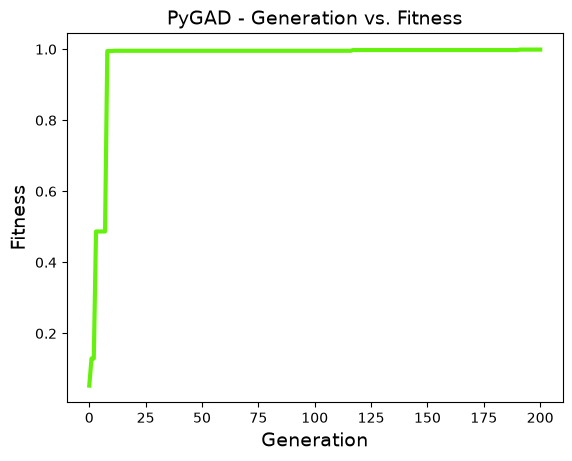

In [14]:
#Grafica de fitness
ga_instance.plot_fitness()

[7.88860905e-31]


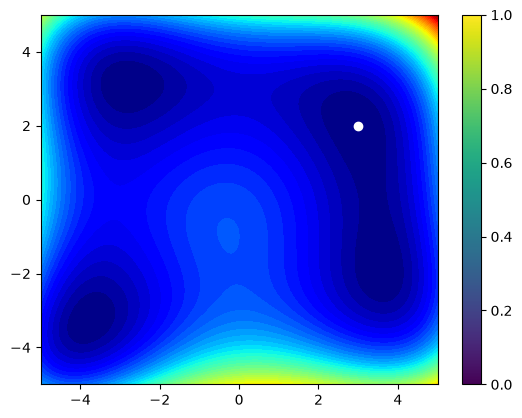

In [15]:
#Grafica de los contornos y punto optimo
plt.contourf(xv, yv, feval, levels=50, cmap='jet')
plt.scatter(xopAG, yopAG,c='white',marker='o')
plt.colorbar()
print(fevalGD)